In [1]:
import pandas as pd

In [3]:
df = pd.read_csv("Company_Data-Copy1.csv")

In [4]:
df.head(5)

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [5]:
import pandas as pd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import seaborn as sns
from collections import Counter
from imblearn.over_sampling import SMOTE,  ADASYN
from imblearn.combine import SMOTETomek, SMOTEENN
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
import plotly.express as px
from plotly.offline import plot as off
import plotly.figure_factory as ff
import plotly.io as pio
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import  DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report,confusion_matrix,accuracy_score, roc_auc_score, roc_curve, precision_recall_curve
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score, train_test_split, RandomizedSearchCV
import warnings
warnings.filterwarnings('ignore')

In [9]:
df.isnull().any()

Sales          False
CompPrice      False
Income         False
Advertising    False
Population     False
Price          False
ShelveLoc      False
Age            False
Education      False
Urban          False
US             False
dtype: bool

In [20]:
df.isnull().sum()

Sales          0
CompPrice      0
Income         0
Advertising    0
Population     0
Price          0
ShelveLoc      0
Age            0
Education      0
Urban          0
US             0
dtype: int64

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Sales        400 non-null    float64
 1   CompPrice    400 non-null    int64  
 2   Income       400 non-null    int64  
 3   Advertising  400 non-null    int64  
 4   Population   400 non-null    int64  
 5   Price        400 non-null    int64  
 6   ShelveLoc    400 non-null    str    
 7   Age          400 non-null    int64  
 8   Education    400 non-null    int64  
 9   Urban        400 non-null    str    
 10  US           400 non-null    str    
dtypes: float64(1), int64(7), str(3)
memory usage: 38.5 KB


In [17]:
df[df.duplicated()]

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US


<Axes: xlabel='count', ylabel='ShelveLoc'>

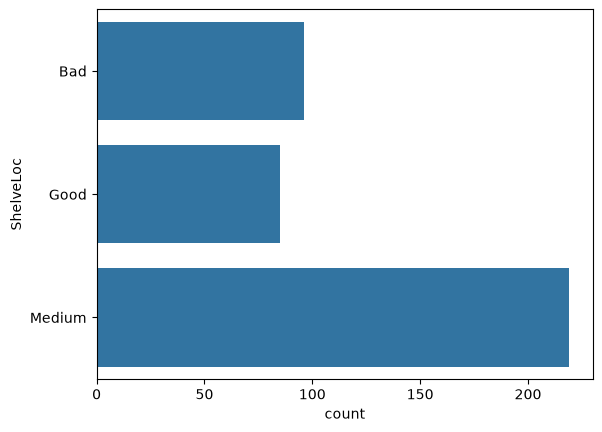

In [21]:
#EDA = exproratery data anlysis

# Univariate analysis = independant analysis of specific column.
# Bivariate anaalysis = when you do anlysis of any two column.
# Multivariate anylysis = when you do anlysis of more than two columns.

# data = 1. numerical :- height , weight , age , mobile prize , (which comes in number )
#        2. categorical :- gender , college name , country , state , (which comes usually in text format )





# categorical data =
# 1.using countplot


sns.countplot(df['ShelveLoc'])


<Axes: >

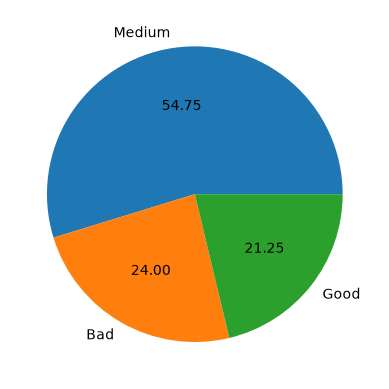

In [23]:
# 2.  use pie chart

df['ShelveLoc'].value_counts().plot(kind = 'pie', autopct = '%.2f')

(array([75., 73., 79., 86., 87.]),
 array([25., 36., 47., 58., 69., 80.]),
 <BarContainer object of 5 artists>)

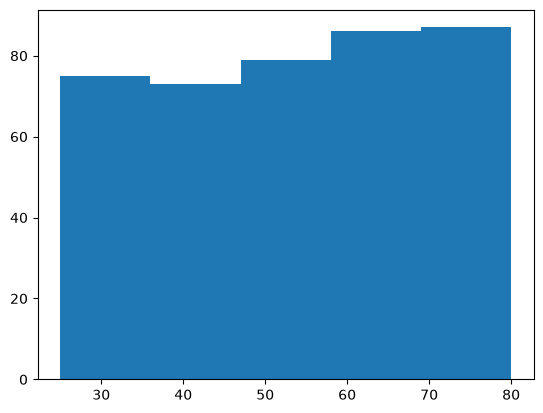

In [8]:
# Numerical data 


# histogram 

plt.hist(df['Age'] , bins = 5)

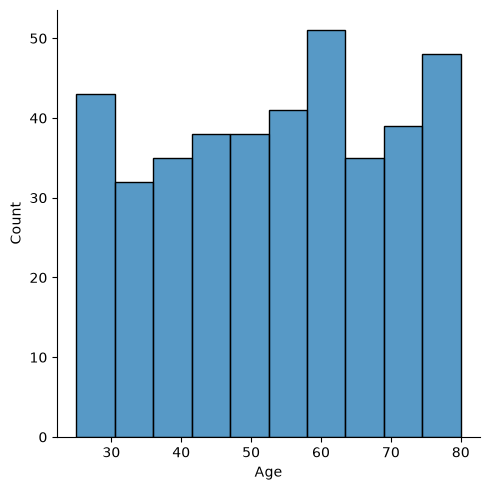

In [31]:
# displot = provide probability

sns.displot(df['Age'])

<Axes: ylabel='Income'>

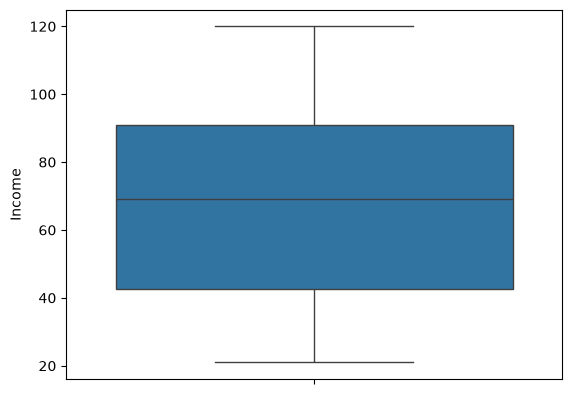

In [35]:
# boxplot = provide 5 number summary 

sns.boxplot(df['Income'])

<Axes: xlabel='Price', ylabel='CompPrice'>

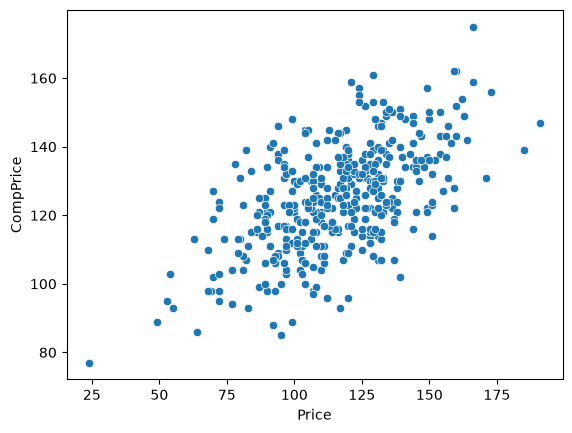

In [6]:
# scatterplot for numarical & numarical


sns.scatterplot(x = df['Price'],y = df['CompPrice'])

<Axes: xlabel='Urban', ylabel='Age'>

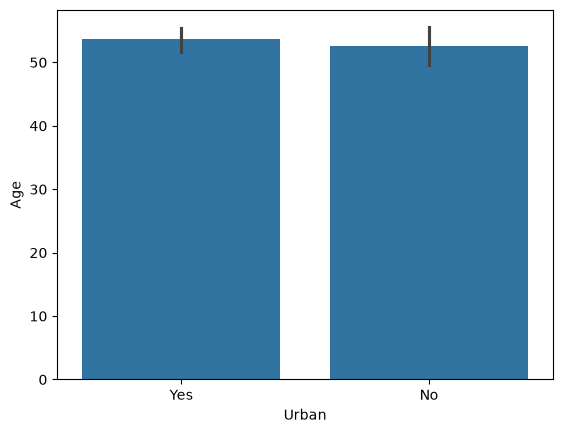

In [19]:
# bar plot = numarical and categorical


sns.barplot(x = df['Urban'], y = df['Age'])

<Axes: xlabel='Age', ylabel='Population'>

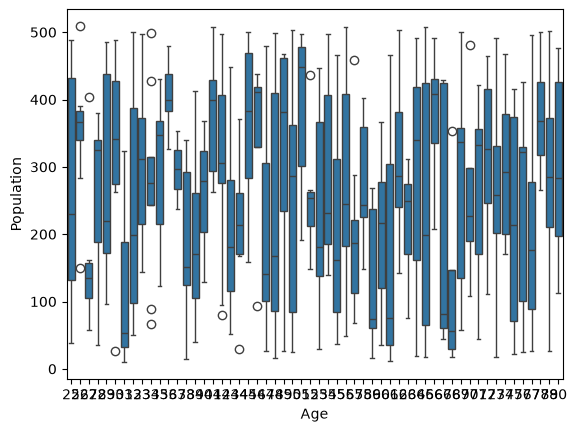

In [25]:
sns.boxplot(x=df['Age'], y=df['Population'])

Task was destroyed but it is pending!
task: <Task pending name='Task-175' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\NIKHIL\AppData\Roaming\Python\Python314\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-176' coro=<Kernel.shell_main() running at C:\Users\NIKHIL\AppData\Roaming\Python\Python314\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\NIKHIL\AppData\Roaming\Python\Python314\site-packages\zmq\eventloop\zmqstream.py:563]>
Task was destroyed but it is pending!
task: <Task pending name='Task-176' coro=<Kernel.shell_main() running at C:\Users\NIKHIL\AppData\Roaming\Python\Python314\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]>


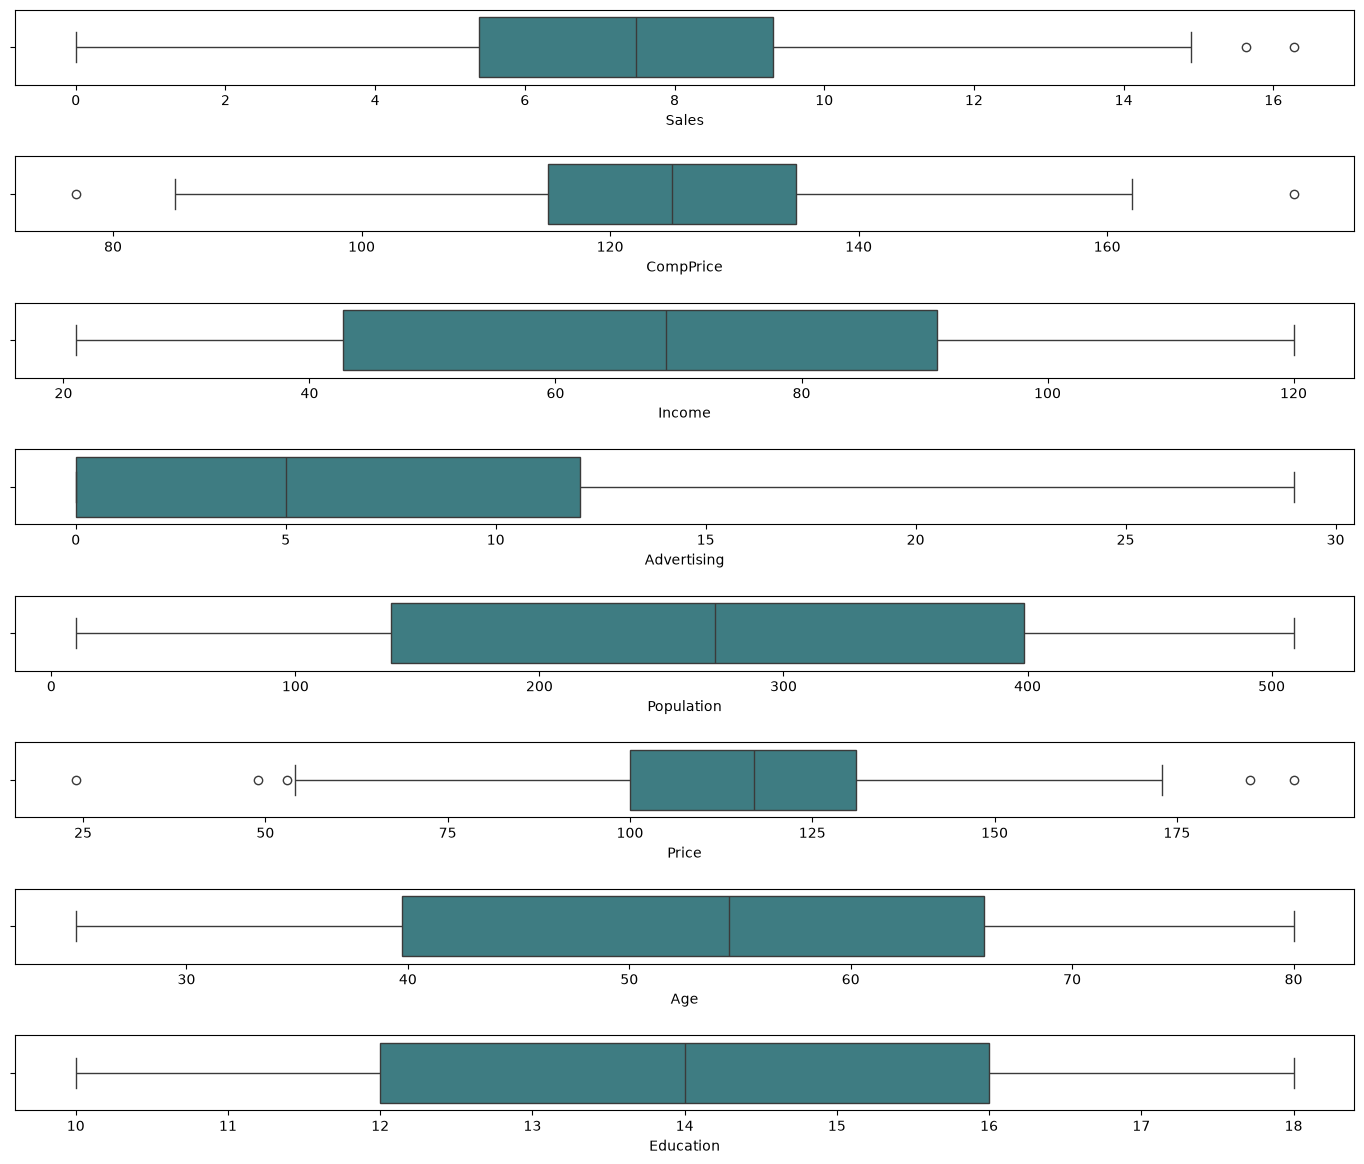

In [26]:
ot=df.copy() 
fig, axes=plt.subplots(8,1,figsize=(14,12),sharex=False,sharey=False)
sns.boxplot(x='Sales',data=ot,palette='crest',ax=axes[0])
sns.boxplot(x='CompPrice',data=ot,palette='crest',ax=axes[1])
sns.boxplot(x='Income',data=ot,palette='crest',ax=axes[2])
sns.boxplot(x='Advertising',data=ot,palette='crest',ax=axes[3])
sns.boxplot(x='Population',data=ot,palette='crest',ax=axes[4])
sns.boxplot(x='Price',data=ot,palette='crest',ax=axes[5])
sns.boxplot(x='Age',data=ot,palette='crest',ax=axes[6])
sns.boxplot(x='Education',data=ot,palette='crest',ax=axes[7])
plt.tight_layout(pad=2.0)

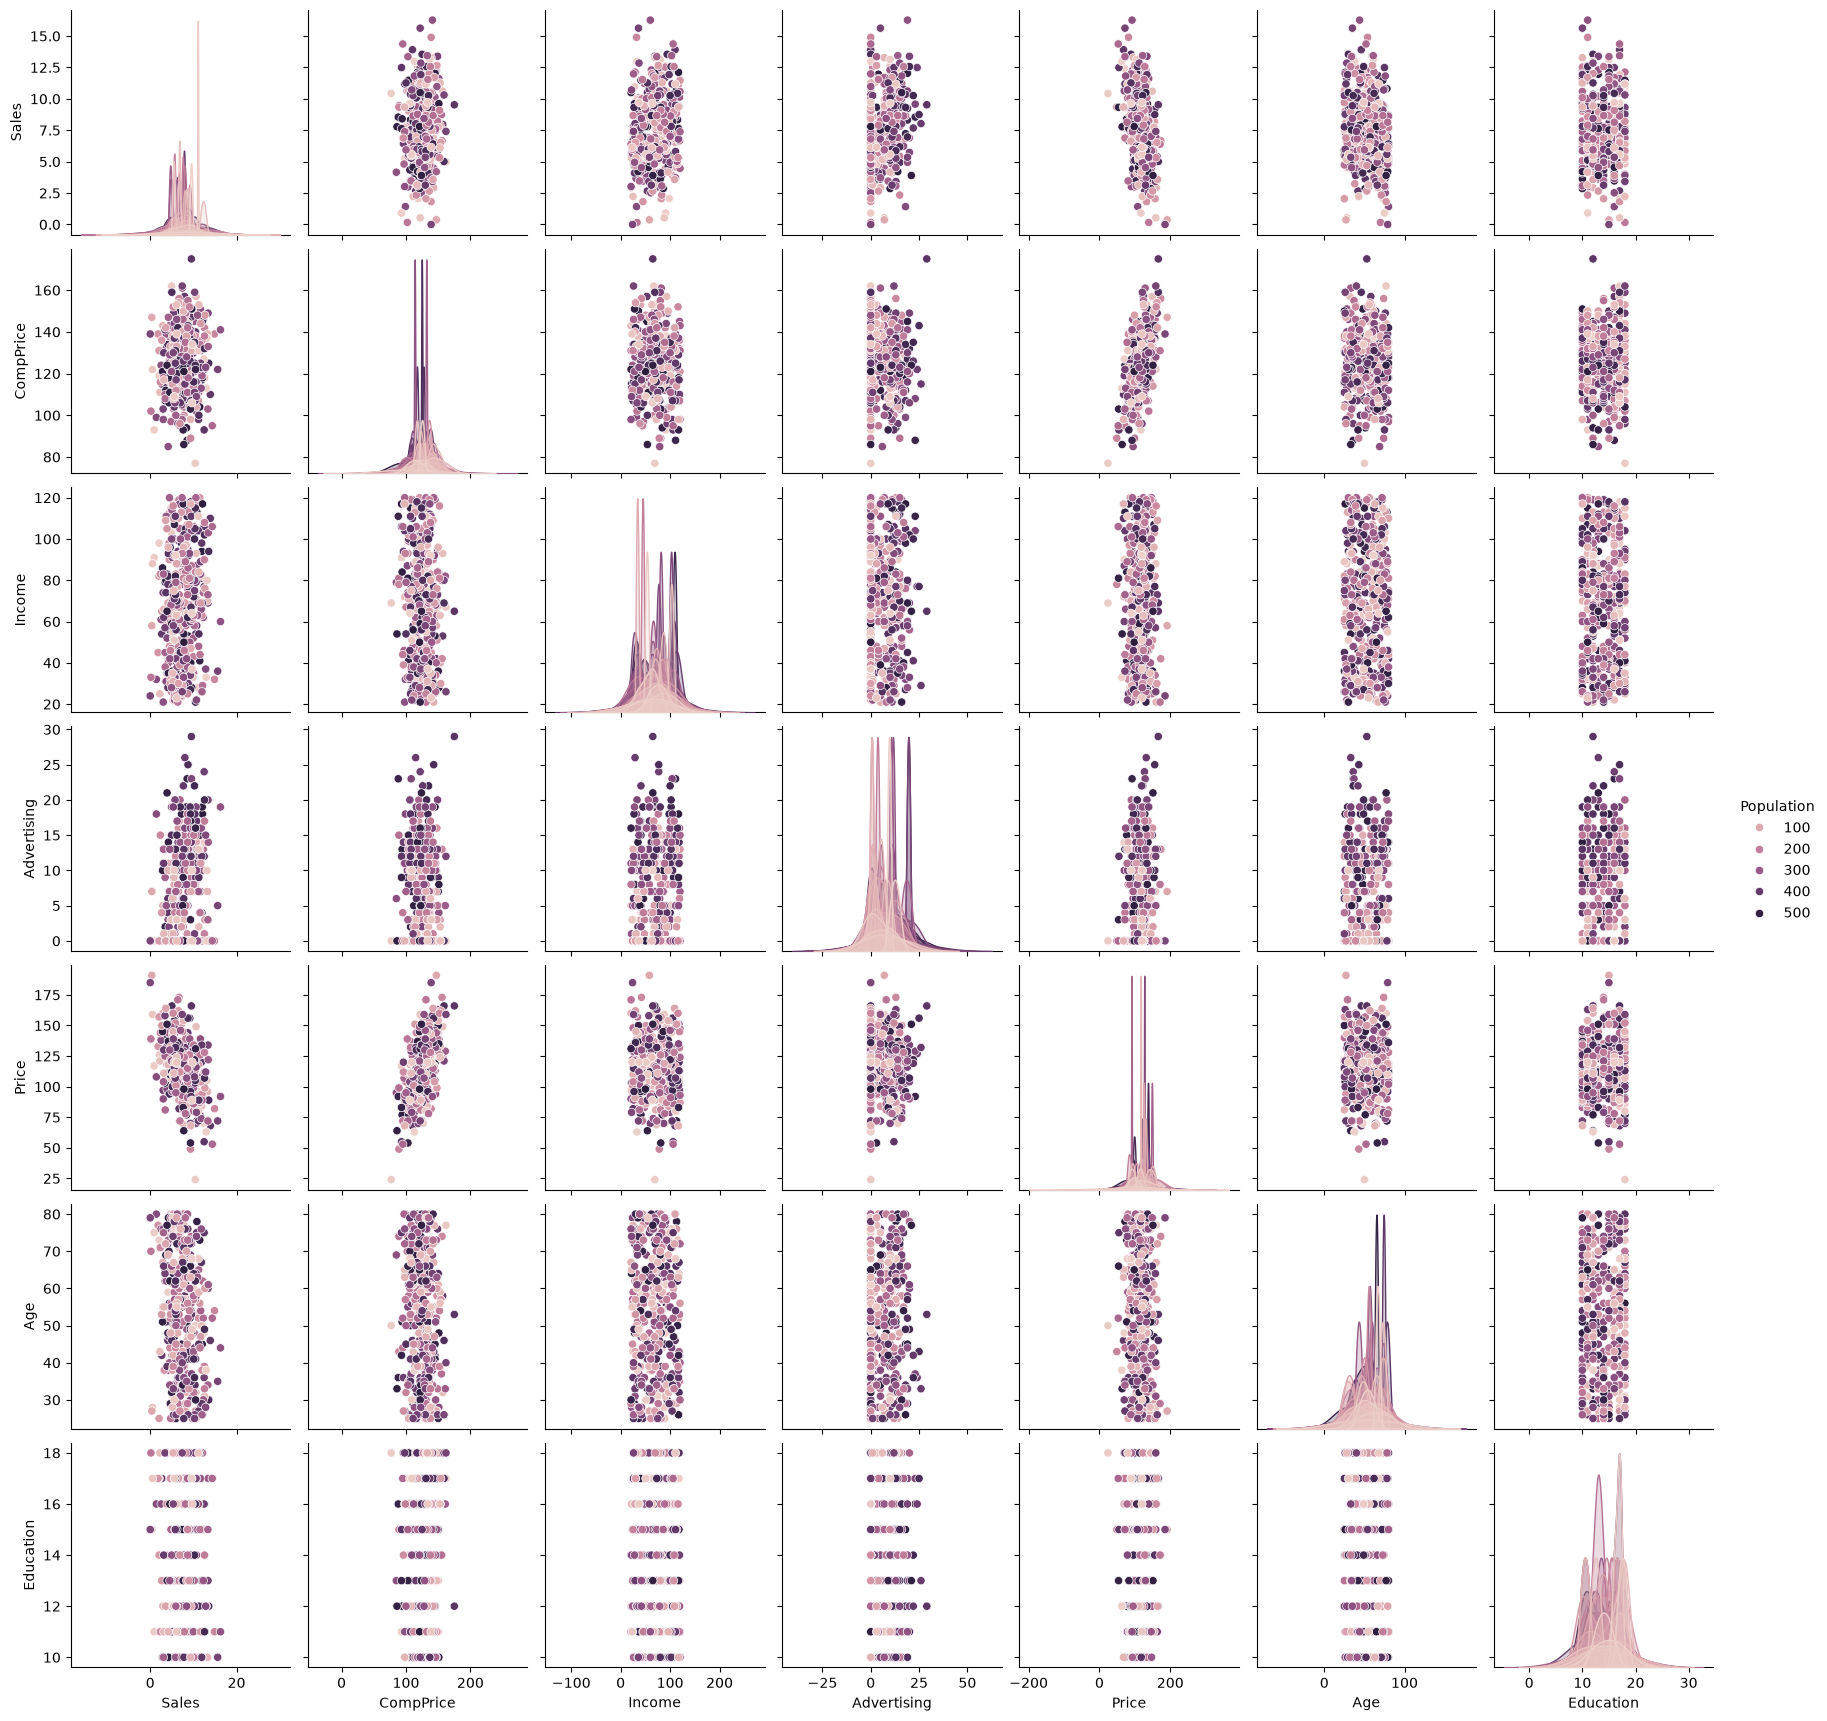

In [28]:
sns.pairplot(df ,hue = 'Population')